In [1]:
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda"
print(device)

cuda


In [2]:
class Cos(nn.Module):
   def __init__(self):
        super().__init__()

       

   def forward(self,t,z):
        x, y = z[...,0], z[...,1]
      
        dx = -2*(torch.cos(x)-torch.sin(x)) - (torch.cos(y)-torch.sin(y))
        dy = -2*(torch.cos(y)-torch.sin(y)) - (torch.cos(x) - torch.sin(x))
        return torch.stack([dx, dy], dim=-1)

In [18]:
def makeDataSet(T=3.0, step=60, noise_std=0.02, nx=20, ny=20,
                x_range=(0.0, 4.5), y_range=(0.0, 4.5)):
    gt = Cos().to(device)
    t = torch.linspace(0.0, T, step, device=device)

    xs = torch.linspace(x_range[0], x_range[1], nx, device=device)
    ys = torch.linspace(y_range[0], y_range[1], ny, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing='ij')

    z0 = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=-1)

    with torch.no_grad():
        z_traj = odeint(gt, z0, t, method="dopri5")
        z_traj = z_traj.transpose(0, 1).contiguous()
        if noise_std > 0:
            z_traj = z_traj + noise_std * torch.randn_like(z_traj)

    return z0, t, z_traj

z0_all, t_eval, Z_all = makeDataSet(T=1.0,step=100,noise_std=0.01,nx=20,ny=20)

N=z0_all.size(0)
perm=torch.randperm(N)


train_idx=perm[: int(0.8*N)] #перемешанные индексы 
test_idx=perm[int(0.8*N):]

z0_train, z0_test = z0_all[train_idx], z0_all[test_idx]
Z_train, Z_test = Z_all[train_idx], Z_all[test_idx]

train_load = DataLoader(TensorDataset(z0_train, Z_train), batch_size=64, shuffle=True)
test_load = DataLoader(TensorDataset(z0_test, Z_test), batch_size=128, shuffle=False)



In [19]:
torch.save({
    "z0_all": z0_all.cpu(),
    "Z_all": Z_all.cpu(),
    "t_eval": t_eval.cpu(),
    "train_idx": train_idx.cpu(),
    "test_idx": test_idx.cpu()
}, "dataset.pt")

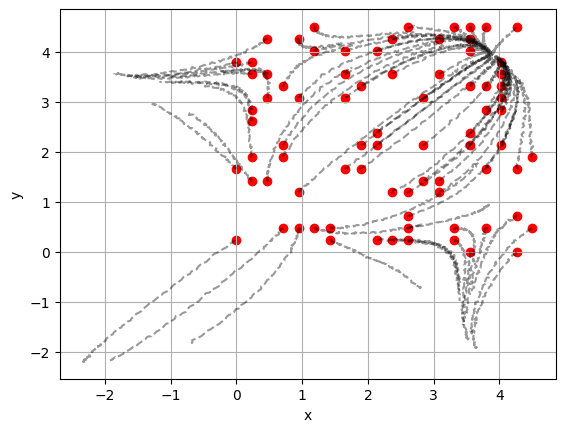

In [20]:


for z0_batch, Z_batch in test_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()
        

In [21]:
class ODEmodel(nn.Module):
    def __init__(self,state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim+(1 if time_dependent else 0)
        self.net=nn.Sequential(
            nn.Linear(in_dim, hidden),nn.Softplus(),
            nn.Linear(hidden, hidden), nn.Softplus(),
            nn.Linear(hidden,state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        

    def forward(self, t,z):
        if z.dim()==1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)
    
class NeuralODE(nn.Module):
     def __init__(self, func, use_adjoint, rtol=1e-3, atol=1e-4, method="dopri5"):
            super().__init__()
            self.func = func
            self.use_adjoint = use_adjoint
            self.rtol = rtol
            self.atol = atol
            self.method = method


     def forward(self,z0,t):
            solver= odeint_adjoint if self.use_adjoint else odeint
            Z = solver(self.func, z0, t , rtol=self.rtol, atol=self.atol, method=self.method)
            return Z.transpose(0, 1).contiguous()



In [30]:
def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count
    
true_equilibria = torch.tensor([
    [math.pi/4,     math.pi/4],     # unstable
    [math.pi/4,     5*math.pi/4],   # saddle
    [5*math.pi/4,   math.pi/4],     # saddle
    [5*math.pi/4,   5*math.pi/4],   # stable
], dtype=torch.float32, device=device)
def jacobian_2d(func, x, t0=0.0):
   

    x = x.clone().detach().requires_grad_(True)
    t0 = torch.tensor(float(t0), device=x.device, dtype=x.dtype)

    
    y = func(t0, x.unsqueeze(0)).squeeze(0)

    J = torch.zeros(2, 2, device=x.device, dtype=x.dtype)

    for i in range(2):
        grad = torch.autograd.grad(y[i], x, retain_graph=True)[0]
        J[i] = grad

    return J

def find_equilibrium(func, x0, t0=0.0, steps=300, lr=0.02):
    x = x0.clone().detach().to(device).requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    t0 = torch.tensor(float(t0), device=device)

    for _ in range(steps):
        v = func(t0, x.unsqueeze(0)).squeeze(0)
        loss = (v**2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()

    with torch.no_grad():
        res = torch.norm(func(t0, x.unsqueeze(0)).squeeze(0)).item()
    return x.detach(), res

In [31]:
def analyze_equilibrium(func, epoch, t0=0.0):
    print(f"\nEpoch {epoch}")

    for i, x_true_eq in enumerate(true_equilibria, 1):
        x0 = x_true_eq + 0.2 * torch.randn_like(x_true_eq)

        x_eq, res = find_equilibrium(func, x0, t0=t0, steps=300, lr=0.02)
        err = torch.norm(x_eq - x_true_eq).item()

        J = jacobian_2d(func, x_eq, t0=t0)
        eigvals = torch.linalg.eigvals(J)

        print(f"\nEquilibrium {i}")
        print("x_equilibrium      =", x_eq.detach().cpu().numpy())
        print("x_true_equilibrium =", x_true_eq.detach().cpu().numpy())
        print("||x_eq - x_true||  =", err)
        print("residual ||f(x)||  =", res)
        print("eigenvalues        =", eigvals.detach().cpu().numpy())

In [32]:
def train(model, loader, t_eval, epochs=300, lr=1e-2, clip_grad=5.0, tag="NODE"):
    optim = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(1, epochs + 1):
        model.train()
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred = model(z0, t_eval)
            loss = mse(Z_pred, Z)

            optim.zero_grad()
            loss.backward()
            if clip_grad:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optim.step()

        if ep % 10 == 0:
            tr = evaluate(model, train_load, t_eval)
            te = evaluate(model, test_load, t_eval)

            print(f"[{tag}] Epoch {ep:03d} | train {tr:.6f} | test {te:.6f}")
            analyze_equilibrium(model.func, epoch=ep, t0=0.0)

    return model

In [33]:


func_adj = ODEmodel().to(device)
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

print("Training Neural ODE ...")
node_adj = train(node_adj, train_load, t_eval, tag="ADJ")

print("\nFinal MSE")
print("Train:", evaluate(node_adj, train_load, t_eval))
print("Test :", evaluate(node_adj, test_load,  t_eval))



torch.save({
    "model_state": node_adj.state_dict(),
    "func_state": node_adj.func.state_dict(),  
}, "node_adj.pth")

Training Neural ODE ...
[ADJ] Epoch 010 | train 0.804666 | test 0.682351

Epoch 10

Equilibrium 1
x_equilibrium      = [-1.7852666 -0.0838029]
x_true_equilibrium = [0.7853982 0.7853982]
||x_eq - x_true||  = 2.713637351989746
residual ||f(x)||  = 0.6167653799057007
eigenvalues        = [0.02964683+0.j 0.28647012+0.j]

Equilibrium 2
x_equilibrium      = [-2.7068145  0.6077888]
x_true_equilibrium = [0.7853982 3.9269907]
||x_eq - x_true||  = 4.81795072555542
residual ||f(x)||  = 0.5835055708885193
eigenvalues        = [0.03358775+0.j 0.25802732+0.j]

Equilibrium 3
x_equilibrium      = [ 0.9419551 -1.5991377]
x_true_equilibrium = [3.9269907 0.7853982]
||x_eq - x_true||  = 3.8205299377441406
residual ||f(x)||  = 0.679276704788208
eigenvalues        = [0.01302338+0.j 0.33877397+0.j]

Equilibrium 4
x_equilibrium      = [-0.7645149 -0.6508129]
x_true_equilibrium = [3.9269907 3.9269907]
||x_eq - x_true||  = 6.554884433746338
residual ||f(x)||  = 0.6457360982894897
eigenvalues        = [0.0234265